In [ ]:
!pip -q install dowhy


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 403.1/403.1 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.9/245.9 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 54.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 45.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 42.3 MB/s eta 0:00:00


In [ ]:
!pip -q install pygraphviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 53.9 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd

np.random.seed(42)
N = 1000

df = pd.DataFrame({
    "tenure_days": np.random.randint(30, 2001, N),
    "previous_orders": np.random.poisson(8, N),
    "days_since_last_order": np.random.randint(1, 181, N),
    "avg_order_value": np.random.lognormal(4, 0.4, N),
    "prior_email_engagement": np.random.randint(0, 11, N),
    "price_sensitivity": np.random.uniform(0, 1, N)
})

discount_score = (
    0.5 * df["price_sensitivity"]
    + 0.3 * (df["days_since_last_order"] / 180)
    - 0.2 * (df["previous_orders"] / 20)
)

prob_discount = 1 / (1 + np.exp(-4 * (discount_score - 0.3)))
df["treatment"] = np.random.binomial(1, prob_discount, N)
df["discount_percent"] = df["treatment"] * 10

purchase_score = (
    -0.5
    + 0.8 * df["treatment"]
    + 0.5 * (df["previous_orders"] / 8)
    + 0.5 * df["prior_email_engagement"] / 10
    - 0.8 * df["price_sensitivity"]
    - 0.003 * df["days_since_last_order"]
)

purchase_probability = 1 / (1 + np.exp(-purchase_score))
df["purchased"] = np.random.binomial(1, purchase_probability, N)

df["revenue"] = np.where(
    df["purchased"] == 1,
    df["avg_order_value"] * (1 - df["discount_percent"] / 100),
    0
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1000, 10)


,tenure_days,previous_orders,days_since_last_order,avg_order_value,prior_email_engagement,price_sensitivity,treatment,discount_percent,purchased,revenue
0,1156,8,111,121.666389,1,0.183563,0,0,0,0.000000
1,1489,2,16,59.687884,9,0.424644,0,0,0,0.000000
2,890,11,53,52.867849,6,0.391956,1,10,1,47.581064
3,1324,5,40,38.807892,6,0.513394,1,10,0,0.000000
4,1160,11,100,34.111501,8,0.809587,0,0,0,0.000000


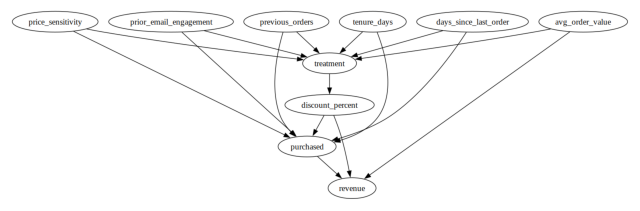

In [ ]:
from dowhy import CausalModel

causal_graph = """
digraph {
    tenure_days -> treatment;
    tenure_days -> purchased;

    previous_orders -> treatment;
    previous_orders -> purchased;

    days_since_last_order -> treatment;
    days_since_last_order -> purchased;

    avg_order_value -> treatment;
    avg_order_value -> revenue;

    prior_email_engagement -> treatment;
    prior_email_engagement -> purchased;

    price_sensitivity -> treatment;
    price_sensitivity -> purchased;

    treatment -> discount_percent;
    discount_percent -> purchased;
    discount_percent -> revenue;

    purchased -> revenue;
}
"""

model = CausalModel(
    data=df,
    treatment="treatment",
    outcome="purchased",
    graph=causal_graph
)

model.view_model()

In [ ]:
identified_estimand = model.identify_effect()

print("Identified causal estimand:")
print(identified_estimand)

Identified causal estimand:
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
     d                                                                         ↪
────────────(E[purchased|days_since_last_order,tenure_days,prior_email_engagem ↪
d[treatment]                                                                   ↪

↪                                        
↪ ent,previous_orders,price_sensitivity])
↪                                        
Estimand assumption 1, Unconfoundedness: If U→{treatment} and U→purchased then P(purchased|treatment,days_since_last_order,tenure_days,prior_email_engagement,previous_orders,price_sensitivity,U) = P(purchased|treatment,days_since_last_order,tenure_days,prior_email_engagement,previous_orders,price_sensitivity)

### Estimand : 2
Estimand name: iv
Estimand expression:
 ⎡                                                               -1⎤
 ⎢        d                     ⎛        d              

In [11]:
identified_estimand = model.identify_effect(
    estimand_type="nonparametric-ate"
)

print("Backdoor identification result:")
print(identified_estimand)

Backdoor identification result:
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
     d                                                                         ↪
────────────(E[purchased|days_since_last_order,tenure_days,prior_email_engagem ↪
d[treatment]                                                                   ↪

↪                                        
↪ ent,previous_orders,price_sensitivity])
↪                                        
Estimand assumption 1, Unconfoundedness: If U→{treatment} and U→purchased then P(purchased|treatment,days_since_last_order,tenure_days,prior_email_engagement,previous_orders,price_sensitivity,U) = P(purchased|treatment,days_since_last_order,tenure_days,prior_email_engagement,previous_orders,price_sensitivity)

### Estimand : 2
Estimand name: iv
Estimand expression:
 ⎡                                                               -1⎤
 ⎢        d                     ⎛        d          